In [4]:
!git clone -b megha-work https://github.com/meghagangal362015/cmpe257-early-reading-prediction.git

%cd cmpe257-early-reading-prediction

Cloning into 'cmpe257-early-reading-prediction'...
remote: Enumerating objects: 68, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 68 (delta 18), reused 49 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (68/68), 942.10 KiB | 3.46 MiB/s, done.
Resolving deltas: 100% (18/18), done.
/content/cmpe257-early-reading-prediction/cmpe257-early-reading-prediction/cmpe257-early-reading-prediction


In [6]:
import pandas as pd

paper_df = pd.read_csv("data/processed/paper_complete_706.csv")

print("Dataset shape:", paper_df.shape)
print(paper_df.head())
print(paper_df.isna().sum().sum(), "missing values")

Dataset shape: (706, 19)
   SchlID  NWFcls  NWFwrc  ORFwc  SAwrS  SAsrS  SAtoS  RMwidRS  RMwdaRS  \
0     1.0    31.0     8.0    8.0  424.0  441.0  459.0     12.0      4.0   
1     1.0    40.0    13.0    9.0  419.0  457.0  472.0     17.0      6.0   
2     1.0    14.0     4.0    8.0  419.0  435.0  450.0      9.0      2.0   
3     1.0    32.0    11.0    8.0  419.0  462.0  468.0     18.0      7.0   
4     1.0    39.0    13.0   13.0  429.0  419.0  457.0     17.0      8.0   

   Gender  Tx  Age1b  Tier2_N  TKPctCrct  grp_rate  rcmistot  gnrl_fid  \
0     1.0   1   85.0     13.0  84.848485  2.301621  3.699074  0.916667   
1     1.0   1   76.0     13.0  84.848485  2.301621  3.699074  0.916667   
2     1.0   1   75.0     13.0  84.848485  2.301621  3.699074  0.916667   
3     1.0   1   80.0     13.0  84.848485  2.301621  3.699074  0.916667   
4     0.0   1   73.0     13.0  84.848485  2.301621  3.699074  0.916667   

   RMwidRS_target  RMwdaRS_target  
0             1.0             1.0  
1      

In [7]:
# Define paper features, targets, and school groups

paper_features = [
    "NWFcls",
    "NWFwrc",
    "ORFwc",
    "SAwrS",
    "SAsrS",
    "SAtoS",
    "RMwidRS",
    "RMwdaRS",
    "Gender",
    "Tx",
    "Age1b",
    "Tier2_N",
    "TKPctCrct",
    "grp_rate",
    "rcmistot",
    "gnrl_fid"
]

X = paper_df[paper_features].copy()
groups = paper_df["SchlID"]

targets = {
    "Word Identification": "RMwidRS_target",
    "Word Attack": "RMwdaRS_target"
}

print("Feature matrix:", X.shape)
print("Number of schools:", groups.nunique())
print("Features:", X.columns.tolist())

Feature matrix: (706, 16)
Number of schools: 42
Features: ['NWFcls', 'NWFwrc', 'ORFwc', 'SAwrS', 'SAsrS', 'SAtoS', 'RMwidRS', 'RMwdaRS', 'Gender', 'Tx', 'Age1b', 'Tier2_N', 'TKPctCrct', 'grp_rate', 'rcmistot', 'gnrl_fid']


In [8]:
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, average_precision_score
import numpy as np

# Identify categorical and numeric features
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Preprocessing performed separately inside each fold
preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

group_kfold = GroupKFold(n_splits=5)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Five-fold grouped cross-validation is ready.")

Numeric features: ['NWFcls', 'NWFwrc', 'ORFwc', 'SAwrS', 'SAsrS', 'SAtoS', 'RMwidRS', 'RMwdaRS', 'Gender', 'Tx', 'Age1b', 'Tier2_N', 'TKPctCrct', 'grp_rate', 'rcmistot', 'gnrl_fid']
Categorical features: []
Five-fold grouped cross-validation is ready.


In [9]:
from sklearn.base import clone

rf_results = []

for target_name, target_column in targets.items():

    y = paper_df[target_column].astype(int)

    print(f"\n{target_name}")

    for fold, (train_index, validation_index) in enumerate(
        group_kfold.split(X, y, groups=groups),
        start=1
    ):
        X_train = X.iloc[train_index]
        X_validation = X.iloc[validation_index]

        y_train = y.iloc[train_index]
        y_validation = y.iloc[validation_index]

        model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=42,
                    class_weight="balanced",
                    n_jobs=-1
                )
            )
        ])

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_validation)[:, 1]
        predictions = model.predict(X_validation)

        accuracy = accuracy_score(y_validation, predictions)
        pr_auc = average_precision_score(
            y_validation,
            probabilities
        )

        rf_results.append({
            "Target": target_name,
            "Fold": fold,
            "Accuracy": accuracy,
            "PR-AUC": pr_auc
        })

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy:.4f}, "
            f"PR-AUC = {pr_auc:.4f}"
        )


Word Identification
Fold 1: Accuracy = 0.6549, PR-AUC = 0.6891
Fold 2: Accuracy = 0.5915, PR-AUC = 0.6260
Fold 3: Accuracy = 0.7357, PR-AUC = 0.8510
Fold 4: Accuracy = 0.5857, PR-AUC = 0.6266
Fold 5: Accuracy = 0.6197, PR-AUC = 0.6671

Word Attack
Fold 1: Accuracy = 0.5493, PR-AUC = 0.6145
Fold 2: Accuracy = 0.6268, PR-AUC = 0.7055
Fold 3: Accuracy = 0.6214, PR-AUC = 0.7453
Fold 4: Accuracy = 0.5071, PR-AUC = 0.5218
Fold 5: Accuracy = 0.6268, PR-AUC = 0.7557


In [10]:
rf_results_df = pd.DataFrame(rf_results)

summary = (
    rf_results_df
    .groupby("Target")[["Accuracy", "PR-AUC"]]
    .agg(["mean", "std"])
    .round(4)
)

print("Random Forest five-fold cross-validation results:")
display(summary)

print("\nIndividual fold results:")
display(rf_results_df)

Random Forest five-fold cross-validation results:


Accuracy          PR-AUC        
                        mean     std    mean     std
Target                                              
Word Attack           0.5863  0.0551  0.6686  0.0992
Word Identification   0.6375  0.0614  0.6920  0.0929


Individual fold results:


,Target,Fold,Accuracy,PR-AUC
0,Word Identification,1,0.654930,0.689135
1,Word Identification,2,0.591549,0.626034
2,Word Identification,3,0.735714,0.850991
3,Word Identification,4,0.585714,0.626571
4,Word Identification,5,0.619718,0.667110
5,Word Attack,1,0.549296,0.614459
6,Word Attack,2,0.626761,0.705542
7,Word Attack,3,0.621429,0.745323
8,Word Attack,4,0.507143,0.521790
9,Word Attack,5,0.626761,0.755710


In [13]:
from sklearn.inspection import permutation_importance

importance_records = []

for target_name, target_column in targets.items():

    y = paper_df[target_column].astype(int)

    for fold, (train_index, validation_index) in enumerate(
        group_kfold.split(X, y, groups=groups),
        start=1
    ):
        X_train = X.iloc[train_index]
        X_validation = X.iloc[validation_index]

        y_train = y.iloc[train_index]
        y_validation = y.iloc[validation_index]

        model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=42,
                    class_weight="balanced",
                    n_jobs=-1
                )
            )
        ])

        model.fit(X_train, y_train)

        permutation = permutation_importance(
            model,
            X_validation,
            y_validation,
            scoring="average_precision",
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )

        for feature, importance in zip(
            paper_features,
            permutation.importances_mean
        ):
            importance_records.append({
                "Target": target_name,
                "Fold": fold,
                "Feature": feature,
                "Importance": importance
            })

importance_df = pd.DataFrame(importance_records)

feature_importance_summary = (
    importance_df
    .groupby(["Target", "Feature"])["Importance"]
    .agg(["mean", "std"])
    .reset_index()
    .sort_values(["Target", "mean"], ascending=[True, False])
    .round(4)
)

display(feature_importance_summary)

,Target,Feature,mean,std
12,Word Attack,Tx,0.0165,0.0102
5,Word Attack,RMwdaRS,0.0104,0.0285
3,Word Attack,NWFwrc,0.0075,0.0116
14,Word Attack,grp_rate,0.0073,0.0184
11,Word Attack,Tier2_N,0.0070,0.0079
7,Word Attack,SAsrS,0.0020,0.0116
15,Word Attack,rcmistot,0.0009,0.0176
6,Word Attack,RMwidRS,-0.0001,0.0088
1,Word Attack,Gender,-0.0021,0.0029
4,Word Attack,ORFwc,-0.0034,0.0119


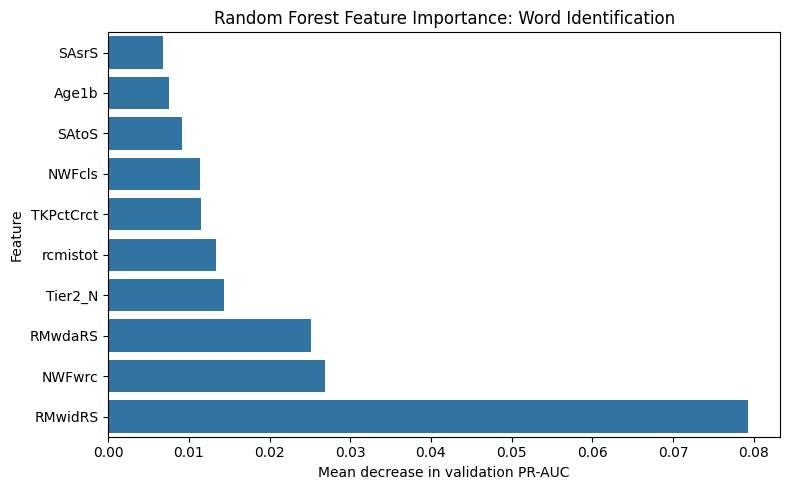

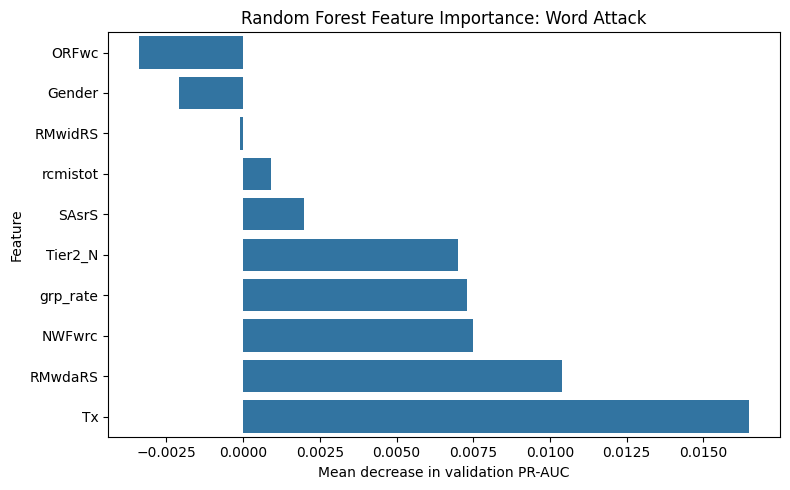

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

for target_name in targets.keys():

    plot_data = (
        feature_importance_summary[
            feature_importance_summary["Target"] == target_name
        ]
        .sort_values("mean", ascending=True)
        .tail(10)
    )

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=plot_data,
        x="mean",
        y="Feature",
        errorbar=None
    )

    plt.title(f"Random Forest Feature Importance: {target_name}")
    plt.xlabel("Mean decrease in validation PR-AUC")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

In [15]:
import os

os.makedirs("results", exist_ok=True)

rf_results_df.to_csv(
    "results/random_forest_cv_fold_results.csv",
    index=False
)

summary.to_csv(
    "results/random_forest_cv_summary.csv"
)

feature_importance_summary.to_csv(
    "results/random_forest_feature_importance.csv",
    index=False
)

print("Random Forest results saved.")

Random Forest results saved.


In [16]:
from google.colab import files

files.download("results/random_forest_cv_fold_results.csv")
files.download("results/random_forest_cv_summary.csv")
files.download("results/random_forest_feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>